# Numerical Methods and Learned Dynamics

Developed from PHYS20762 Computational Physics coursework by Ruijia Liu (2025/2026).

This notebook compares numerical integrators for a damped and driven oscillator, then trains an MLP on one simulated trajectory to contrast one-step prediction with recursive rollout.

The system is $m\ddot{x}+b\dot{x}+kx=F(t)$, with $m=4.62$ kg and $k=3.34$ N/m. All data are generated in the notebook. See README.md for execution instructions and limitations.


## Python Environment Setup

Before performing the numerical simulations, the required Python libraries for numerical computation and visualisation are imported.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Physical Model and Numerical Setup

We study the damped harmonic oscillator governed by

$$
m x''(t) + b x'(t) + k x(t) = F(t)
$$

Assigned parameters:

$$
m = 4.62 \text{ kg}, \quad k = 3.34 \text{ kg s}^{-2}
$$

Initial conditions:

$$
x(0) = 0, \quad v(0) = -1
$$

The undamped natural angular frequency is

$$
\omega_0 = \sqrt{\frac{k}{m}}
$$

which defines the natural timescale of the system. This frequency provides a natural reference scale against which the numerical time step $h$ can be compared.

### Physical parameters and initial conditions

Define helper functions for the oscillator parameters $m$, $k$, $b$, and the default initial conditions $x_0$ and $v_0$ used in the simulations.

In [2]:
def get_params(m=4.62, k=3.34, b=0.0):
    """Return dictionary of physical parameters."""
    return {"m": float(m), "k": float(k), "b": float(b)}

def default_initial_conditions():
    """Return x0, v0."""
    return 0.0, -1.0

### Time grid generation

The time discretisation is kept uniform to ensure consistent comparison across numerical schemes.  
This function generates the time array from $t_0$ to $t_{\text{end}}$ with step size $h$, and returns both the time grid and the number of time steps.

In [3]:
def time_grid(t0, t_end, h):
    """Generate time array up to (and not exceeding) t_end."""
    n = int(np.floor((t_end - t0) / h)) + 1
    t = t0 + h * np.arange(n)
    return t, n

# 2. Reformulation as First-Order System

The second-order equation is rewritten as:

$$
x' = v
$$

$$
v' = \frac{F(t) - b v - k x}{m}
$$

All numerical methods update the state vector $(x, v)$.

$$
\mathbf{y}(t) =
\begin{pmatrix}
x(t) \\
v(t)
\end{pmatrix}.
$$

$$
\mathbf{y}'(t) = \mathbf{f}(t, \mathbf{y}),
$$

where

$$
\mathbf{f}(t, \mathbf{y}) =
\begin{pmatrix}
v \\
\dfrac{F(t) - b v - k x}{m}
\end{pmatrix}.
$$

where the right-hand side defines the dynamical system governing the evolution of the oscillator.

### Force and acceleration

Define the external force $F(t)$ and a function to compute the acceleration from the equation of motion of the damped oscillator.

In [4]:
def F_zero(t):
    """External force F(t)=0."""
    return 0.0

def acceleration(x, v, t, params, F):
    """Compute acceleration a(t) from ODE."""
    m, b, k = params["m"], params["b"], params["k"]
    return (F(t) - b * v - k * x) / m

### External force models

External forces are implemented as callable functions to allow flexible testing of different forcing scenarios.  
Here we define a sinusoidal driving force and a short rectangular push that can be used in the simulations.

In [5]:
def rect_push(t, t_push, duration, F0):
    """Rectangular pulse: F=F0 for t in [t_push, t_push+duration], else 0."""
    return float(F0) if (t_push <= t <= t_push + duration) else 0.0


def F_sine_factory(F0, omega):
    """Return function F(t)=F0*sin(omega*t)."""
    F0, omega = float(F0), float(omega)
    return lambda t: F0 * np.sin(omega * t)


def F_push_factory(t_push, duration, F0):
    """Return function for rectangular push."""
    t_push, duration, F0 = float(t_push), float(duration), float(F0)
    return lambda t: rect_push(t, t_push, duration, F0)

# 3. Implementation of numerical methods

To solve the equation of motion of the damped oscillator numerically,

$$
m\ddot{x} + b\dot{x} + kx = F(t)
$$

we rewrite it as a first-order system

$$
\dot{x} = v, \qquad
\dot{v} = \frac{F(t) - bv - kx}{m}.
$$

We implement several standard time-integration schemes.

### Euler method

$$
x_{n+1} = x_n + h v_n
$$

$$
v_{n+1} = v_n + h a_n
$$

### Improved Euler (Heun method)

Predictor step:

$$
x^* = x_n + h v_n
$$

$$
v^* = v_n + h a_n
$$

Corrector step:

$$
x_{n+1} = x_n + \frac{h}{2}(v_n + v^*)
$$

$$
v_{n+1} = v_n + \frac{h}{2}(a_n + a^*)
$$

### Euler–Cromer method

$$
v_{n+1} = v_n + h a_n
$$

$$
x_{n+1} = x_n + h v_{n+1}
$$

### Position Verlet
The position Verlet method is strictly valid for forces that do not depend on velocity. 
In the present system the damping term introduces a velocity dependence, therefore the velocity is estimated numerically when applying this scheme.
$$
x_{n+1} = 2x_n - x_{n-1} + h^2 a_n
$$

The velocity can then be estimated using

$$
v_n \approx \frac{x_{n+1} - x_{n-1}}{2h}.
$$

### Time-stepping functions

Implementation of the update rules for each numerical integration method (Euler, Improved Euler/Heun, Euler–Cromer, and Verlet).

In [6]:
def step_euler(x, v, t, h, params, F):
    a = acceleration(x, v, t, params, F)
    x_new = x + h * v
    v_new = v + h * a
    return x_new, v_new

def step_improved_euler(x, v, t, h, params, F):
    # Heun / improved Euler on first-order system
    a0 = acceleration(x, v, t, params, F)
    x_star = x + h * v
    v_star = v + h * a0
    a_star = acceleration(x_star, v_star, t + h, params, F)
    x_new = x + 0.5 * h * (v + v_star)
    v_new = v + 0.5 * h * (a0 + a_star)
    return x_new, v_new

def step_euler_cromer(x, v, t, h, params, F):
    a = acceleration(x, v, t, params, F)
    v_new = v + h * a
    x_new = x + h * v_new
    return x_new, v_new

def step_verlet_init(x0, v0, t0, h, params, F):
    """
    Start-up for position-Verlet:
    Need x1 using Taylor: x1 = x0 + h v0 + 0.5 h^2 a0
    And v1 via finite difference using a0 and a1 (or central approx).
    We'll compute x1, then estimate v1 using v0 + 0.5 h (a0 + a1).
    """
    a0 = acceleration(x0, v0, t0, params, F)
    x1 = x0 + h * v0 + 0.5 * h * h * a0

    # estimate v at t0+h
    # predict v1 with Euler to evaluate a1 consistently
    v1_pred = v0 + h * a0
    a1 = acceleration(x1, v1_pred, t0 + h, params, F)
    v1 = v0 + 0.5 * h * (a0 + a1)

    return x0, x1, v1  # (x_prev, x_curr, v_curr)

def step_verlet(x_prev, x_curr, v_curr, t, h, params, F):
    """
    Approximate start-up for a position-Verlet-like scheme.

    Standard position Verlet is strictly valid when acceleration does not
    depend explicitly on velocity. For the damped oscillator, the damping
    term introduces velocity dependence, so this initialisation is only
    approximate.
    """
    a_n = acceleration(x_curr, v_curr, t, params, F)
    x_next = 2.0 * x_curr - x_prev + (h * h) * a_n
    v_next = (x_next - x_prev) / (2.0 * h)
    return x_curr, x_next, v_next  # new (x_prev, x_curr, v_curr)

### Integration driver

Define functions to run a chosen numerical method over the full time interval, and to apply all methods for comparison.

In [7]:
def integrate(method_name, t0, t_end, h, x0, v0, params, F=F_zero):
    """
    Run chosen integration method.
    Return arrays t, x, v.
    """
    t, n = time_grid(t0, t_end, h)
    x = np.zeros(n, dtype=float)
    v = np.zeros(n, dtype=float)
    x[0], v[0] = float(x0), float(v0)

    name = method_name.lower().strip()
    if name in ["euler", "explicit euler"]:
        for i in range(n - 1):
            x[i+1], v[i+1] = step_euler(x[i], v[i], t[i], h, params, F)

    elif name in ["improved euler", "heun", "euler-heun", "euler heun"]:
        for i in range(n - 1):
            x[i+1], v[i+1] = step_improved_euler(x[i], v[i], t[i], h, params, F)

    elif name in ["euler-cromer", "euler cromer", "cromer"]:
        for i in range(n - 1):
            x[i+1], v[i+1] = step_euler_cromer(x[i], v[i], t[i], h, params, F)

    elif name in ["verlet", "position verlet"]:
        # approximate position-Verlet treatment for the damped system
        if n < 2:
            return t, x, v
        x_prev, x_curr, v_curr = step_verlet_init(x0, v0, t0, h, params, F)
        x[0] = x_prev
        x[1] = x_curr
        v[1] = v_curr

        # set initial velocity at t0
        v[0] = v0

        for i in range(1, n - 1):
            # i corresponds to current index
            x_prev, x_curr, v_curr = step_verlet(x_prev, x_curr, v_curr, t[i], h, params, F)
            x[i+1] = x_curr
            v[i+1] = v_curr

    else:
        raise ValueError(f"Unknown method_name: {method_name}")

    return t, x, v

def run_all_methods(t0, t_end, h, x0, v0, params, F=F_zero):
    methods = ["Euler", "Improved Euler", "Euler-Cromer", "Verlet"]
    out = {}
    for m in methods:
        out[m] = integrate(m, t0, t_end, h, x0, v0, params, F)
    return out

# 4. Analytical Benchmark Solution (F = 0)

Define

$$
\omega_0 = \sqrt{\frac{k}{m}}, \quad
\gamma = \frac{b}{2m}
$$

The solution depends on whether the system is:

- Underdamped
- Critically damped
- Overdamped

The code automatically selects the correct regime.

### Analytical solution function

The following code defines the analytical solution for the undriven oscillator, with the correct damping regime selected automatically.

In [8]:
def omega0(params):
    return np.sqrt(params["k"] / params["m"])

def b_critical(params):
    # b_cr^2 = 4 k m
    return 2.0 * np.sqrt(params["k"] * params["m"])

def analytic_solution(t, x0, v0, params):
    """
    Return x_analytic(t), v_analytic(t) for F=0.
    Handles underdamped, critical, overdamped regimes.
    """
    t = np.asarray(t, dtype=float)
    m, b, k = params["m"], params["b"], params["k"]
    w0 = np.sqrt(k / m)
    gamma = b / (2.0 * m)

    # Use tolerance for critical comparison
    tol = 1e-10
    disc = w0*w0 - gamma*gamma

    if disc > tol:
        # underdamped
        wd = np.sqrt(disc)
        # Solve for A, phi from initial conditions
        # x(0) = A cos(phi) = x0
        # v(0) = -gamma A cos(phi) - wd A sin(phi) = v0
        # Let C = A cos(phi) = x0
        # Let S = A sin(phi) = -(v0 + gamma x0)/wd
        C = x0
        S = -(v0 + gamma * x0) / wd
        A = np.sqrt(C*C + S*S)
        phi = np.arctan2(S, C)

        x = A * np.exp(-gamma * t) * np.cos(wd * t + phi)
        v = A * np.exp(-gamma * t) * (-gamma * np.cos(wd * t + phi) - wd * np.sin(wd * t + phi))
        return x, v

    elif abs(disc) <= tol:
        # critical damping: x = (C1 + C2 t) e^{-w0 t}
        # x(0)=C1 = x0
        # v(0)=C2 - w0 C1 = v0 => C2 = v0 + w0 x0
        C1 = x0
        C2 = v0 + w0 * x0
        x = (C1 + C2 * t) * np.exp(-w0 * t)
        v = (C2 - w0 * (C1 + C2 * t)) * np.exp(-w0 * t)
        return x, v

    else:
        # overdamped: roots r1, r2 = -gamma ± sqrt(gamma^2 - w0^2)
        alpha = np.sqrt(gamma*gamma - w0*w0)
        r1 = -gamma + alpha
        r2 = -gamma - alpha
        # x(0)=C1 + C2 = x0
        # v(0)=C1 r1 + C2 r2 = v0
        # Solve:
        # C1 = (v0 - r2 x0)/(r1 - r2)
        # C2 = x0 - C1
        C1 = (v0 - r2 * x0) / (r1 - r2)
        C2 = x0 - C1
        x = C1 * np.exp(r1 * t) + C2 * np.exp(r2 * t)
        v = C1 * r1 * np.exp(r1 * t) + C2 * r2 * np.exp(r2 * t)
        return x, v

The analytical solution provides an exact reference against which numerical errors are quantified in the next section.

# 5. Comparison of Methods (F = 0)

Numerical results are compared against the analytical solution.

Suitable values of $b$ and $h$ are chosen to clearly show differences.

The analytical solution is evaluated on the same discrete time grid as the numerical methods to ensure a consistent pointwise error comparison.

### Comparison setup

Define the configuration, error metric, and plotting utilities used to compare the numerical solutions with the analytical benchmark.

In [9]:
def default_cmp_config():
    """
    Step 5 config (F=0 comparison).

    b_factor: choose damping b = b_factor * b_critical(params)
    h: time step
    t0, t_end: simulation time window
    plot_error: plot |x_num - x_exact|
    plot_phase: plot phase portrait (x vs v)
    print_errors: print RMS error table
    """
    return dict(
        b_factor=0.1,
        h=0.1,
        t0=0.0,
        t_end=50.0,
        plot_error=True,
        plot_phase=True,
        print_errors=True,
    )

def error_rmse(x_num, x_ref):
    """Return RMS error between numerical and reference arrays."""
    diff = np.asarray(x_num) - np.asarray(x_ref)
    return np.sqrt(np.mean(diff * diff))

def _plot_multi(curves, xlabel, ylabel, title=None, grid_alpha=0.3):
    """
    Plot multiple curves on a single figure.

    curves: dict label -> (x, y)
    """
    plt.figure()
    for label, (x, y) in curves.items():
        plt.plot(x, y, label=label)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if title:
        plt.title(title)
    plt.legend()
    plt.grid(True, alpha=grid_alpha)
    plt.show()


def compare_methods_F0(config=None):
    """
    Run all numerical methods for F=0 and compare against analytical solution.

    Assumption (important for error computation):
    - run_all_methods(...) returns results on the SAME time grid as time_grid(t0,t_end,h)
      so that x_num and x_exact are pointwise comparable.

    Returns:
        results: dict method -> (t, x, v)
        analytic: (t, x_exact, v_exact)
        params: dict with m,k,b,...
        errors: dict method -> RMS error in x(t)
    """
    base = default_cmp_config()
    cfg = base if config is None else {**base, **config}

    # --- physics parameters ---
    params = get_params()
    params["b"] = float(cfg["b_factor"] * b_critical(params))

    # --- numerical parameters ---
    t0, t_end, h = cfg["t0"], cfg["t_end"], cfg["h"]
    x0, v0 = default_initial_conditions()

    # --- run numerical methods ---
    results = run_all_methods(t0, t_end, h, x0, v0, params, F_zero)

    # --- analytical reference on the same grid ---
    t, _ = time_grid(t0, t_end, h)
    x_exact, v_exact = analytic_solution(t, x0, v0, params)

    # 1) x(t) comparison
    xt_curves = {name: (t_num, x_num) for name, (t_num, x_num, v_num) in results.items()}
    xt_curves["Analytical"] = (t, x_exact)
    _plot_multi(
        xt_curves,
        xlabel="t (s)",
        ylabel="x (m)",
        title=f"Comparison (F=0): b={params['b']:.3g} kg/s, h={h:g} s"
    )

    # 2) RMS errors in x(t)
    errors = {}
    for name, (t_num, x_num, v_num) in results.items():
        errors[name] = error_rmse(x_num, x_exact)

    if cfg["print_errors"]:
        print("RMS error in x(t) vs analytical:")
        for name in sorted(errors.keys()):
            print(f"  {name:15s} {errors[name]:.5e}")

    # 3) |error|(t)
    if cfg["plot_error"]:
        err_curves = {name: (t_num, np.abs(x_num - x_exact))
                      for name, (t_num, x_num, v_num) in results.items()}
        _plot_multi(
            err_curves,
            xlabel="t (s)",
            ylabel=r"|x_num - x_exact| (m)",
            title="Absolute error evolution"
        )

    # 4) phase portrait (x vs v)
    if cfg["plot_phase"]:
        phase_curves = {name: (x_num, v_num) for name, (t_num, x_num, v_num) in results.items()}
        phase_curves["Analytical"] = (x_exact, v_exact)
        _plot_multi(
            phase_curves,
            xlabel="x (m)",
            ylabel="v (m/s)",
            title="Phase space comparison"
        )

    return results, (t, x_exact, v_exact), params, errors

Parameter choice (F = 0)

To clearly highlight differences between numerical integration methods,
we choose an underdamped regime and a moderately large time step.

- Damping is set to a fraction of the critical damping:
  b = 0.1 b_cr, where b_cr^2 = 4km.
- Time step: h = 0.2 s.
  This is large enough to expose stability differences (especially for Euler),
  but small enough to resolve the oscillations.
- Simulation time: 0–50 s,
  covering several oscillation periods to observe cumulative phase error.

The analytical solution is evaluated on the same discrete time grid
as the numerical methods to ensure consistent pointwise error comparison.

### Run the comparison

Run the comparison using a chosen configuration of time step $h$, damping $b$, and simulation duration.

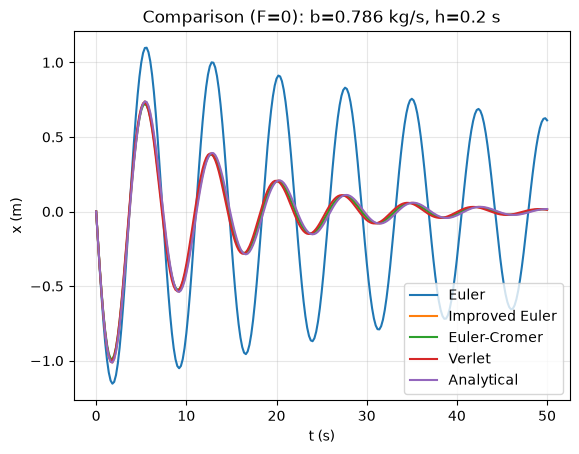

RMS error in x(t) vs analytical:
  Euler           4.41519e-01
  Euler-Cromer    2.11990e-02
  Improved Euler  9.76057e-03
  Verlet          3.75756e-02


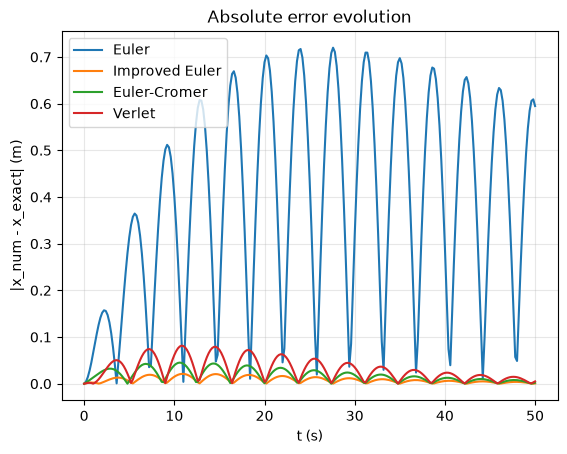

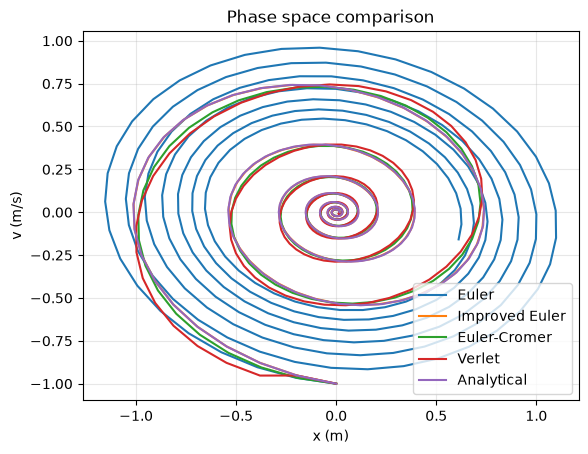

In [10]:
cfg = dict(h=0.2, t_end=50, b_factor=0.1, plot_error=True, plot_phase=True)
results, analytic, params, errors = compare_methods_F0(cfg)

In contrast, Improved Euler and Euler–Cromer closely follow the analytical solution. 
The Verlet method remains stable but exhibits a slightly larger error.

The RMS error confirms that Improved Euler performs best for this time step, 
followed by Euler–Cromer, while the explicit Euler method performs significantly worse.

# 6. Effect of time step on accuracy

To investigate convergence behaviour, we analyse how the numerical error
depends on the time step h.

The error is measured using the RMS difference between numerical and analytical
solutions:

$$
E(h) = sqrt( mean( (x_num - x_exact)^2 ) )
$$

If a method has global order p, we expect:

$$
E(h) ~ h^p
$$

Therefore, on a log–log plot of E versus h, the slope should be approximately p.

### Error scaling and convergence analysis

Define functions to compute the RMS error as a function of the time step $h$, plot the error on a log–log scale, and estimate the convergence order of each numerical method.

In [11]:
def error_rmse(x_num, x_ref):
    """Return RMS error between numerical and analytical solution."""
    diff = np.asarray(x_num) - np.asarray(x_ref)
    return np.sqrt(np.mean(diff * diff))


def compute_error_vs_h(method_name, h_list, t0, t_end, x0, v0, params):
    """
    Compute RMS error as a function of time step h
    for a given numerical method (F=0).
    """
    h_list = np.asarray(h_list, dtype=float)
    errs = []

    for h in h_list:
        t, x_num, v_num = integrate(method_name, t0, t_end, h, x0, v0, params, F_zero)
        x_ref, v_ref = analytic_solution(t, x0, v0, params)
        errs.append(error_rmse(x_num, x_ref))

    return h_list, np.asarray(errs)


def error_sweep_all_methods(h_list, t0, t_end, x0, v0, params):
    """
    Compute error vs h for all implemented methods.
    """
    methods = ["Euler", "Improved Euler", "Euler-Cromer", "Verlet"]
    out = {}

    for m in methods:
        out[m] = compute_error_vs_h(m, h_list, t0, t_end, x0, v0, params)

    return out


def plot_error_vs_h(results, title=None):
    """Log-log plot of error versus time step."""
    plt.figure()

    for method, (h_vals, errs) in results.items():
        plt.loglog(h_vals, errs, 'o-', label=method)

    plt.xlabel("Time step h")
    plt.ylabel("RMS error")
    if title:
        plt.title(title)

    plt.legend()
    plt.grid(True, which="both", alpha=0.3)
    plt.show()


def estimate_convergence_order(results):
    """Estimate convergence order from log-log slope."""
    print("Estimated convergence orders:")

    for method, (h_vals, errs) in results.items():
        coeff = np.polyfit(np.log(h_vals), np.log(errs), 1)
        p = coeff[0]
        print(f"{method:15s} p ≈ {p:.3f}")

### Run convergence test

Fix the physical parameters in the underdamped regime and evaluate how the numerical error varies with the time step $h$.

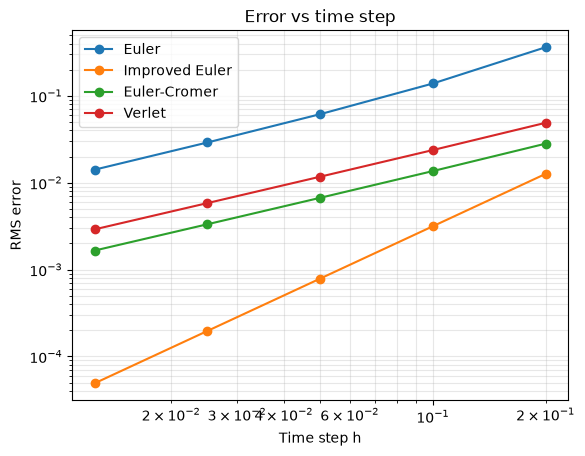

Estimated convergence orders:
Euler           p ≈ 1.162
Improved Euler  p ≈ 2.002
Euler-Cromer    p ≈ 1.021
Verlet          p ≈ 1.017


In [12]:
# Fix physical parameters (underdamped case)

params = get_params()
params["b"] = 0.1* b_critical(params)

x0, v0 = default_initial_conditions()

# Time step values

h_list = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])

# Run sweep

results_h = error_sweep_all_methods(h_list, 0.0, 20.0, x0, v0, params)

# Plot scaling

plot_error_vs_h(results_h, title="Error vs time step")

# Estimate orders

estimate_convergence_order(results_h)

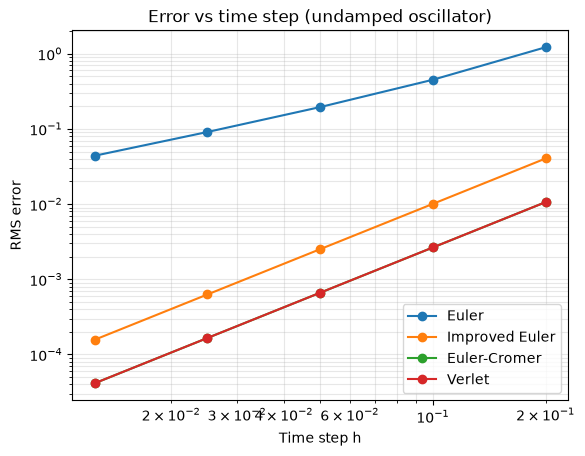

Estimated convergence orders:
Euler           p ≈ 1.189
Improved Euler  p ≈ 2.002
Euler-Cromer    p ≈ 2.001
Verlet          p ≈ 2.001


In [13]:
# Undamped case (b = 0)

params_undamped = get_params()
params_undamped["b"] = 0.0

x0, v0 = default_initial_conditions()

h_list = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])

results_h_undamped = error_sweep_all_methods(
    h_list, 0.0, 20.0, x0, v0, params_undamped
)

plot_error_vs_h(results_h_undamped,
                title="Error vs time step (undamped oscillator)")

estimate_convergence_order(results_h_undamped)

### Convergence behaviour

The fitted slopes concern position RMSE over the stated time-step range. With damping, the recorded slopes are near first order for Euler, Euler-Cromer and the approximate Verlet variant, and near second order for Improved Euler. In the undamped case, Improved Euler and Verlet position errors are near second order. Euler-Cromer also shows this behaviour for the particular initial condition $x_0=0$; it is not evidence that the full method is generally second order.

The Verlet implementation stores a centred velocity estimate associated with the preceding position step and reuses it for damping. It should be read as a coursework approximation for velocity-dependent forces, not a general damped velocity-Verlet integrator.


# 7. Determination of optimal method

Based on quantitative comparison and stability analysis,
the optimal numerical integration method is selected.

For the tested damped case, Improved Euler has the smallest position RMSE among these four implementations and an approximately second-order error slope. It is used for the remaining simulations. This is a comparison at the stated steps and parameters, rather than a general claim of optimality or a long-time stability benchmark.

The retained Verlet implementation is approximate when damping is present; its lower observed order is specific to that implementation.


Based on the convergence study in Step 6, a time step of h = 0.05 s is chosen as a compromise between numerical accuracy and computational cost.

# 8. Damping regimes

Using the critical damping value

$$
b_{cr} = 2\sqrt{km},
$$

we investigate three cases:

- $0.5\,b_{cr}$
- $b_{cr}$
- $2\,b_{cr}$

### Behaviour in different damping regimes

Compare the oscillator motion in the underdamped, critically damped, and overdamped regimes by varying the damping coefficient relative to the critical value $b_{\mathrm{cr}}$.

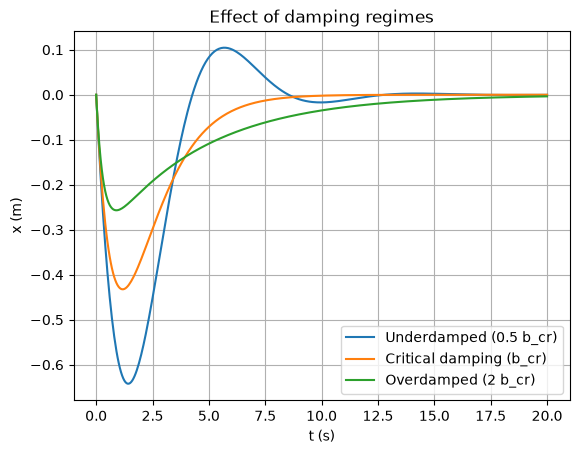

In [14]:
params = get_params()
bcr = b_critical(params)

x0, v0 = default_initial_conditions()

cases = {
    "Underdamped (0.5 b_cr)": 0.5 * bcr,
    "Critical damping (b_cr)": bcr,
    "Overdamped (2 b_cr)": 2 * bcr
}

plt.figure()

for label, b in cases.items():

    params["b"] = b

    t, x, v = integrate(
        "Improved Euler",
        0,          # t0
        20,         # t_end
        0.05,        # step size
        x0,
        v0,
        params,
        F_zero
    )

    plt.plot(t, x, label=label)

plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.title("Effect of damping regimes")
plt.legend()
plt.grid(True)
plt.show()

The three damping regimes produce qualitatively different motion.

For the underdamped case (b = 0.5 b_cr), the system oscillates
while the amplitude gradually decreases due to energy dissipation.

At critical damping (b = b_cr), the system returns to equilibrium
without oscillating and does so in the shortest possible time.

For the overdamped case (b = 2 b_cr), the motion is also
non-oscillatory but the return to equilibrium is slower than
for critical damping.

These numerical results reproduce the theoretical behaviour of
the damped harmonic oscillator.

# 9. External forcing

The oscillator is now studied in the presence of external forces.

Two types of forcing are considered:

• A short rectangular push (impulse-like forcing)  
• A sinusoidal driving force  

These illustrate the transient and steady-state responses
of the damped oscillator.

### Transient response to a short force pulse

Apply a short rectangular force pulse to the oscillator and observe the resulting transient motion.  
After the external push ends, the system evolves as a freely damped oscillator.

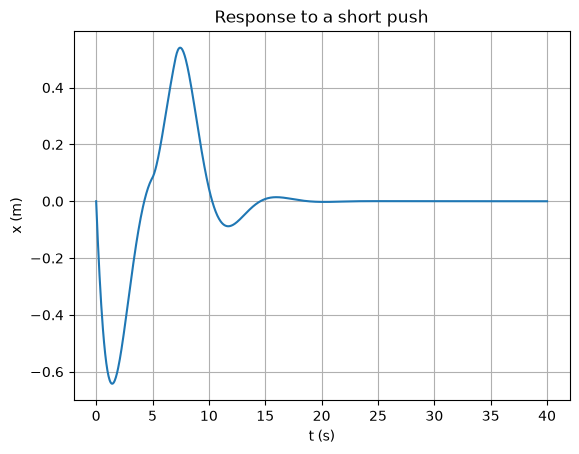

In [15]:
params = get_params()
bcr = b_critical(params)
params["b"] = 0.5 * bcr

x0, v0 = default_initial_conditions()

F_push = F_push_factory(t_push=5, duration=2, F0=2)

t, x, v = integrate("Improved Euler", 0, 40, 0.05, x0, v0, params, F_push)

plt.figure()
plt.plot(t, x)
plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.title("Response to a short push")
plt.grid(True)
plt.show()

### Sinusoidal driving force

Apply a sinusoidal driving force $F(t)=F_0\sin(\omega t)$ and observe the system response.  
The initial transient decays due to damping, leaving steady-state oscillations driven by the external force.

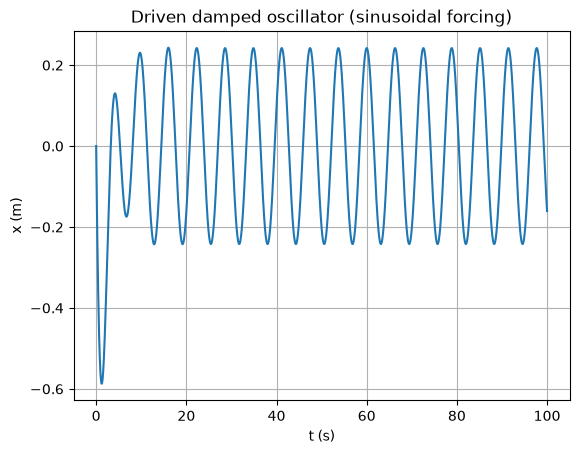

In [16]:
params = get_params()
bcr = b_critical(params)

params["b"] = 0.5 * bcr   # moderate damping

x0, v0 = default_initial_conditions()

# driving parameters
F0 = 1.0
omega = 1.0

F_drive = F_sine_factory(F0, omega)

t, x, v = integrate(
    "Improved Euler",
    0,          # t0
    100,        # longer time to see steady state
    0.05,       # time step
    x0,
    v0,
    params,
    F_drive
)

plt.figure()
plt.plot(t, x)

plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.title("Driven damped oscillator (sinusoidal forcing)")
plt.grid(True)
plt.show()

A short rectangular push produces a transient response.
Once the force is removed, the oscillator behaves like a
free damped oscillator and the motion gradually decays.

For sinusoidal forcing the system initially exhibits a
transient response determined by the initial conditions.
As time progresses, the transient component decays due
to damping and the oscillator settles into a steady-state
oscillation.

In the steady state the motion occurs at the same frequency
as the driving force, which is a characteristic property of
driven damped oscillators.

# 10. Resonance curve (stretch section)

## 10.1 Amplitude response

For a sinusoidally driven damped oscillator, the steady-state motion can be written as

$$
x(t)=A(\omega)\sin(\omega t-\phi),
$$

where $A(\omega)$ is the oscillation amplitude and $\phi$ is the phase lag relative to the driving force.

The amplitude depends on the driving frequency according to

$$
A(\omega)=\frac{F_0/m}{\sqrt{(\omega_0^2-\omega^2)^2+\left(\frac{b\omega}{m}\right)^2}},
$$

where $\omega_0=\sqrt{k/m}$ is the natural frequency of the undamped system.

As the driving frequency varies, the amplitude exhibits a characteristic resonance peak near the resonance frequency $\omega_r$, which is slightly smaller than $\omega_0$ when damping is present.

### Resonance curve and steady-state amplitude

For each driving frequency $\omega$, integrate the driven damped oscillator until the transient response has decayed, then estimate the steady-state amplitude $A(\omega)$. This allows the resonance curve to be constructed and the resonance frequency to be identified numerically.

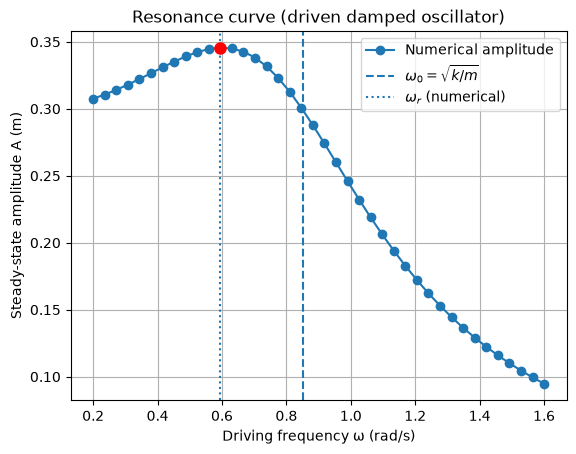

Natural frequency ω0 = 0.850 rad/s
Numerical resonance ωr ≈ 0.595 rad/s


In [17]:
def steady_state_amplitude(t, x, frac_steady=0.5):
    """
    Estimate steady-state amplitude from the last frac_steady fraction of data.
    Uses A = (max - min)/2 over the selected window.
    """
    n = len(t)
    i0 = int((1.0 - frac_steady) * n)
    x_ss = x[i0:]
    return 0.5 * (np.max(x_ss) - np.min(x_ss))


def resonance_curve(omega_list, F0=1.0, b_factor=0.5,
                    t0=0.0, t_end=200.0, h=0.05, frac_steady=0.5):
    """
    Compute resonance curve A(omega) for sinusoidal forcing.
    b is set as b_factor * b_critical.
    """
    params = get_params()
    bcr = b_critical(params)
    params["b"] = b_factor * bcr

    x0, v0 = default_initial_conditions()

    A_list = []

    for omega in omega_list:
        F_drive = F_sine_factory(F0, omega)

        t, x, v = integrate("Improved Euler", t0, t_end, h, x0, v0, params, F_drive)

        A = steady_state_amplitude(t, x, frac_steady=frac_steady)
        A_list.append(A)

    return np.asarray(omega_list, dtype=float), np.asarray(A_list, dtype=float), params


# ----- choose frequency range -----
params_tmp = get_params()
omega0_val = omega0(params_tmp)  # natural frequency (undamped)

omega_list = np.linspace(0.2, 1.6, 40)

# ----- run resonance sweep -----
omega_vals, A_vals, params_used = resonance_curve(
    omega_list,
    F0=1.0,
    b_factor=0.5,     # underdamped but not too sharp
    t_end=200.0,      # long enough to reach steady state
    h=0.05,
    frac_steady=0.5
)

# ----- find numerical resonance frequency -----
i_peak = np.argmax(A_vals)
omega_res = omega_vals[i_peak]
A_res = A_vals[i_peak]

# ----- plot resonance curve -----
plt.figure()

plt.plot(omega_vals, A_vals, "o-", label="Numerical amplitude")

# natural frequency
plt.axvline(omega0_val, linestyle="--", label=r"$\omega_0=\sqrt{k/m}$")

# resonance frequency
plt.axvline(omega_res, linestyle=":", label=r"$\omega_r$ (numerical)")

# mark the peak
plt.plot(omega_res, A_res, "ro", markersize=8)

plt.xlabel("Driving frequency ω (rad/s)")
plt.ylabel("Steady-state amplitude A (m)")
plt.title("Resonance curve (driven damped oscillator)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Natural frequency ω0 = {omega0_val:.3f} rad/s")
print(f"Numerical resonance ωr ≈ {omega_res:.3f} rad/s")

The steady-state amplitude was measured as a function of the driving
frequency ω for a sinusoidally driven damped oscillator.

The resulting resonance curve exhibits a clear peak at approximately
ω ≈ 0.6 rad s⁻¹. The undamped natural frequency of the system is

ω₀ = √(k/m) ≈ 0.85 rad s⁻¹.

For a damped oscillator the resonance frequency is expected to be
slightly smaller than the natural frequency, which is consistent with
the numerical result.

The amplitude decreases for both smaller and larger driving
frequencies, producing the characteristic resonance peak.

## 10.2 Phase difference

For sinusoidal forcing, the steady-state displacement is $x(t)=A(\omega)\sin(\omega t-\phi)$. Its phase lag is $\phi=\operatorname{atan2}(b\omega,k-m\omega^2)$. The lag reaches $\pi/2$ at the undamped natural frequency $\omega_0=\sqrt{k/m}$, which differs from the damped amplitude-resonance frequency. It approaches zero at low frequency and $\pi$ at high frequency.


### Phase difference between driving force and response

For each driving frequency $\omega$, the phase difference between the external force $F(t)=F_0\sin(\omega t)$ and the oscillator displacement $x(t)$ is estimated after the transient response has decayed.

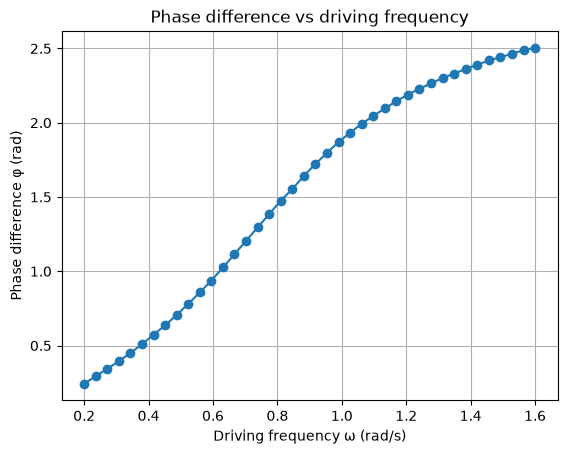

In [18]:
def phase_difference(t, x, omega, frac_steady=0.5):
    """
    Estimate the phase lag between the driving force F(t)=F0 sin(ωt)
    and the oscillator displacement x(t) using the steady-state part
    of the trajectory.
    """
    n = len(t)
    i0 = int((1-frac_steady)*n)

    t_ss = t[i0:]
    x_ss = x[i0:]

    # displacement peak
    i_peak = np.argmax(x_ss)
    t_peak_x = t_ss[i_peak]

    # driving force peak
    t_peak_F = np.pi/(2*omega)

    dt = t_peak_x - t_peak_F

    phi = (omega * dt) % (2*np.pi)
    phi = abs(phi)
    if phi > np.pi:
        phi = 2*np.pi - phi

    return phi


params = get_params()
params["b"] = 0.5*b_critical(params)

x0, v0 = default_initial_conditions()

omega_vals = np.linspace(0.2,1.6,40)

phi_vals = []

for omega in omega_vals:

    F_drive = F_sine_factory(F0=1, omega=omega)

    t,x,v = integrate(
        "Improved Euler",
        0,200,0.05,
        x0,v0,
        params,
        F_drive
    )

    phi = phase_difference(t,x,omega)

    phi_vals.append(phi)


plt.figure()

plt.plot(omega_vals,phi_vals,"o-")

plt.xlabel("Driving frequency ω (rad/s)")
plt.ylabel("Phase difference φ (rad)")
plt.title("Phase difference vs driving frequency")

plt.grid(True)

plt.show()

The sampled-peak phase estimate increases through the frequency range. This estimator is limited by the integration time step and the finite steady-state window; it is not a high-precision phase fit. The theoretical $\pi/2$ crossing occurs at $\omega_0$, not at the lower-frequency amplitude maximum.


## 10.3 Frequency limits

The shape of the resonance curve can also be understood by analysing the limiting behaviour of the driving frequency.

In the low-frequency limit ($\omega \rightarrow 0$), the oscillator responds quasi-statically and the spring force approximately balances the driving force

$$
kx \approx F_0.
$$

This gives an approximate amplitude

$$
A \approx \frac{F_0}{k}.
$$

For the parameters used in the simulation ($F_0 = 1$, $k = 3.34$), this predicts $A \approx 0.30\,\text{m}$, which agrees well with the numerical results at small driving frequency.

In the high-frequency limit ($\omega \rightarrow \infty$), the inertia term dominates the dynamics,

$$
m\ddot{x} \approx F_0\sin(\omega t),
$$

leading to the approximate scaling

$$
A \approx \frac{F_0}{m\omega^2}.
$$

This predicts that the oscillation amplitude decreases rapidly with increasing driving frequency, which is consistent with the behaviour observed in the numerical resonance curve.

### Low- and high-frequency limits of the response

Compare the numerical resonance curve with the expected asymptotic limits.  
For low driving frequency, the amplitude approaches $A \approx F_0/k$, while for high frequency the response decreases as $A \approx F_0/(m\omega^2)$.

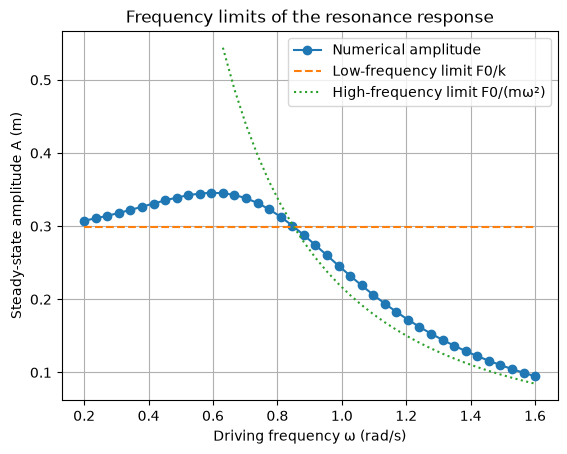

In [19]:
m = params["m"]
k = params["k"]

A_low = np.full_like(omega_vals, F0/k)
A_high = F0/(m*omega_vals**2)

plt.figure()

plt.plot(omega_vals, A_vals, "o-", label="Numerical amplitude")

plt.plot(omega_vals, A_low, "--", label="Low-frequency limit F0/k")

mask = omega_vals > 0.6
plt.plot(omega_vals[mask], A_high[mask], ":", label="High-frequency limit F0/(mω²)")

plt.xlabel("Driving frequency ω (rad/s)")
plt.ylabel("Steady-state amplitude A (m)")
plt.title("Frequency limits of the resonance response")

plt.legend()
plt.grid(True)
plt.show()

The numerical resonance curve is consistent with the expected limiting behaviour of a driven damped oscillator. 
At low driving frequencies the motion becomes quasi-static and the amplitude approaches the constant value $A \approx F_0/k$. 
At high frequencies the response decreases rapidly and follows the approximate scaling $A \approx F_0/(m\omega^2)$. 
These limits explain the overall shape of the resonance curve observed in the simulation.

# 11. Initiative section

## 11.1 Effect of damping on the resonance curve

To further explore the behaviour of the driven oscillator, we investigate how
the resonance curve depends on the damping coefficient.

The resonance amplitude is computed for several values of the damping
coefficient:

- 0.2 b_cr
- 0.5 b_cr
- 0.8 b_cr

This allows us to observe how damping modifies the height and width of the
resonance peak.

### Effect of damping on the resonance curve

Compare the resonance curves for different damping strengths to show how increasing damping reduces the peak amplitude and broadens the response.

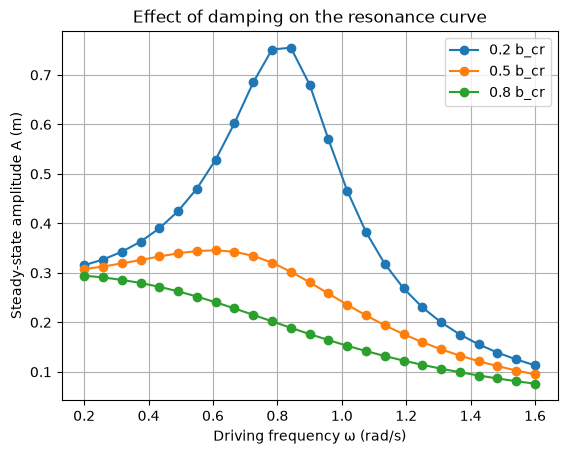

In [20]:
params = get_params()
x0, v0 = default_initial_conditions()
bcr = b_critical(params)

b_values = {
    "0.2 b_cr": 0.2*bcr,
    "0.5 b_cr": 0.5*bcr,
    "0.8 b_cr": 0.8*bcr
}

omega_vals = np.linspace(0.2, 1.6, 25)

plt.figure()

for label, b in b_values.items():

    params["b"] = b
    amps = []

    for omega in omega_vals:

        F_drive = F_sine_factory(F0=1, omega=omega)

        t, x, v = integrate(
            "Improved Euler",
            0, 100, 0.05,
            x0, v0,
            params,
            F_drive
        )

        x_ss = x[len(x)//2:]
        A = (np.max(x_ss) - np.min(x_ss))/2
        amps.append(A)

    plt.plot(omega_vals, amps, "o-", label=label)

plt.xlabel("Driving frequency ω (rad/s)")
plt.ylabel("Steady-state amplitude A (m)")
plt.title("Effect of damping on the resonance curve")
plt.legend()
plt.grid(True)
plt.show()

Reducing the damping coefficient produces a higher and sharper resonance
peak, while stronger damping lowers the peak amplitude and broadens the
resonance curve. For sufficiently large damping the resonance becomes
weak and the peak is less pronounced.

## 11.2 Effect of driving amplitude

We also investigate how the resonance curve changes with the strength
of the external driving force F₀.

### Resonance curves for different $F_0$

Compare the resonance curves for different driving amplitudes $F_0$ to show how the steady-state response scales with the strength of the external force.

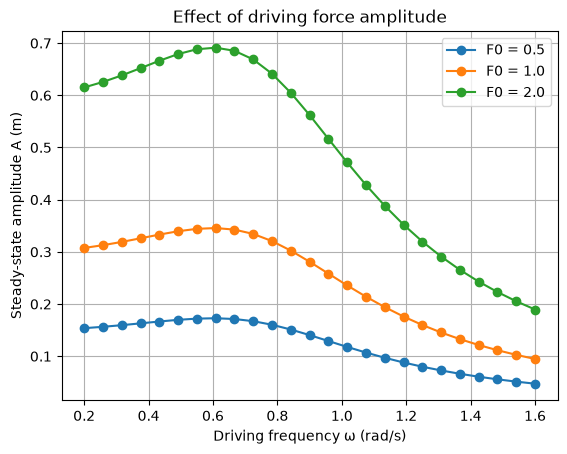

In [21]:
params = get_params()
x0, v0 = default_initial_conditions()
params["b"] = 0.5*b_critical(params)

F_values = {
    "F0 = 0.5": 0.5,
    "F0 = 1.0": 1.0,
    "F0 = 2.0": 2.0
}

omega_vals = np.linspace(0.2, 1.6, 25)

plt.figure()

for label, F0 in F_values.items():

    amps = []

    for omega in omega_vals:

        F_drive = F_sine_factory(F0, omega)

        t, x, v = integrate(
            "Improved Euler",
            0, 100, 0.05,
            x0, v0,
            params,
            F_drive
        )

        x_ss = x[len(x)//2:]
        A = (np.max(x_ss) - np.min(x_ss))/2
        amps.append(A)

    plt.plot(omega_vals, amps, "o-", label=label)

plt.xlabel("Driving frequency ω (rad/s)")
plt.ylabel("Steady-state amplitude A (m)")
plt.title("Effect of driving force amplitude")
plt.legend()
plt.grid(True)
plt.show()

Changing the driving amplitude scales the steady-state oscillation
amplitude but does not shift the resonance frequency. This confirms that
the oscillator behaves linearly within the range of parameters considered.

## 11.3 Learning the dynamics with a neural network

Instead of numerically integrating the ODE directly, we train a neural network
to learn the one-step time-advance map

(x_n, v_n, t_n) → (x_{n+1}, v_{n+1})

The trained model is then rolled forward iteratively to generate an entire
trajectory, which is compared with the numerical solution.

### Machine-learning approximation of the dynamics

Train a neural network to learn the one-step update map $(x_n, v_n, t_n)\rightarrow(x_{n+1}, v_{n+1})$, then roll out the learned model over time and compare its trajectory with the numerical solution.

Test R^2 score = 0.9993


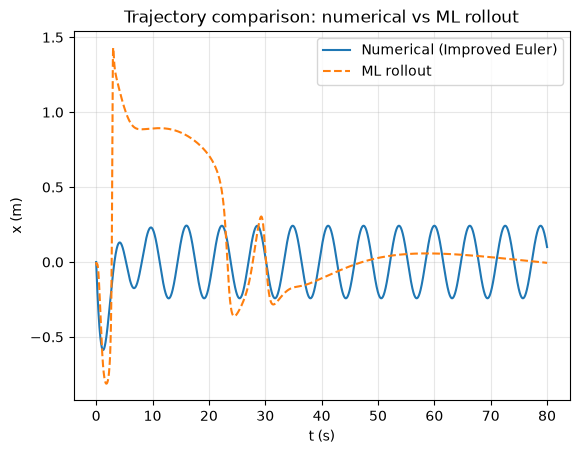

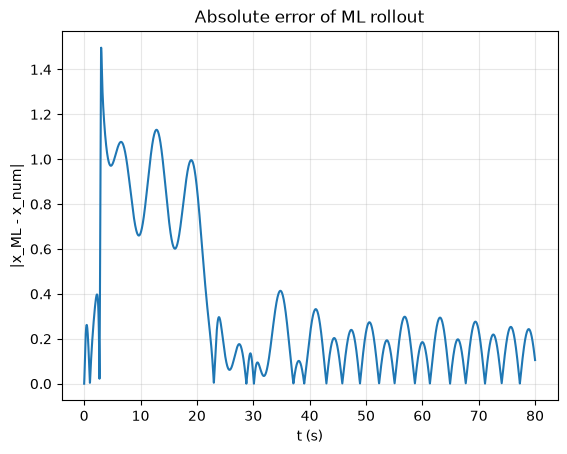

In [22]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split


def make_step_dataset(t, x, v):
    """Build supervised dataset for one-step prediction."""
    X = np.column_stack([x[:-1], v[:-1], t[:-1]])
    Y = np.column_stack([x[1:],  v[1:]])
    return X, Y


def rollout_ml(model, t, x0, v0):
    """Roll out ML model for the given time array t."""
    x_pred = np.zeros_like(t, dtype=float)
    v_pred = np.zeros_like(t, dtype=float)
    x_pred[0], v_pred[0] = x0, v0

    for i in range(len(t) - 1):
        inp = np.array([[x_pred[i], v_pred[i], t[i]]])
        out = model.predict(inp)[0]
        x_pred[i+1], v_pred[i+1] = out[0], out[1]

    return x_pred, v_pred


# ----- Generate training data from numerical solver -----

params = get_params()
bcr = b_critical(params)
params["b"] = 0.5 * bcr

x0, v0 = default_initial_conditions()

h = 0.02
t_end = 80.0

# choose one scenario for training (pick either F_zero or sinusoidal forcing)
F0, omega = 1.0, 1.0
F_drive = F_sine_factory(F0, omega)

t, x, v = integrate("Improved Euler", 0.0, t_end, h, x0, v0, params, F_drive)

X, Y = make_step_dataset(t, x, v)

# ----- Train/test split -----

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, shuffle=True, random_state=0
)

# ----- Train model -----

model = MLPRegressor(
    hidden_layer_sizes=(64, 64),
    activation="tanh",
    solver="adam",
    max_iter=3000,
    random_state=0
)

model.fit(X_train, Y_train)

score = model.score(X_test, Y_test)
print(f"Test R^2 score = {score:.4f}")

# ----- Roll out and compare -----

x_ml, v_ml = rollout_ml(model, t, x0, v0)

plt.figure()
plt.plot(t, x, label="Numerical (Improved Euler)")
plt.plot(t, x_ml, "--", label="ML rollout")
plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.title("Trajectory comparison: numerical vs ML rollout")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
plt.plot(t, np.abs(x_ml - x))
plt.xlabel("t (s)")
plt.ylabel("|x_ML - x_num|")
plt.title("Absolute error of ML rollout")
plt.grid(True, alpha=0.3)
plt.show()

The MLP learns $(x_n,v_n,t_n)\rightarrow(x_{n+1},v_{n+1})$ from one sinusoidally driven trajectory. A random 80/20 split mixes nearby time points from that same trajectory, so the reported one-step $R^2$ is an interpolation diagnostic, not an independent-trajectory or long-horizon generalisation test.

During recursive rollout the model receives its own predicted states, so errors can accumulate and inputs can move away from the training trajectory. The numerical reference remains periodically driven; damping removes the transient but does not make this forced system converge to $x=0$. A learned rollout drifting towards zero is therefore a failure to reproduce the driven motion, not physical stabilisation.


# 12. Conclusions

This study connects analytical references, numerical convergence and the limits of learned dynamics.


The fixed-step and convergence comparisons show that the tested integrators can have substantially different errors. Improved Euler retains approximately second-order position accuracy in the damped sweep. The approximate Verlet implementation has lower observed order with damping; the undamped position experiment behaves differently.

The driven simulations reproduce transient decay, a damped amplitude-resonance peak and the response to changing force amplitude. These results use finite frequency grids and observation windows.

The neural-network extension illustrates a key limitation: accurate one-step predictions on randomly held-out points from one trajectory do not ensure an accurate recursive rollout. No speedup, cross-parameter generalisation or robust surrogate model is claimed.
